In [1]:
print("Banking Fraud Detection Project Started!")

print("Let's detect fraudulent transactions using Machine Learning.")

Banking Fraud Detection Project Started!
Let's detect fraudulent transactions using Machine Learning.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib
import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
DATA_PATH = r"C:\FraudDetection\ml-service\data\creditcard_transactions.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (284807, 31)


In [5]:
df.columns.tolist()

['Time',
 'V1',
 'V2',
 'V3',
 'V4',
 'V5',
 'V6',
 'V7',
 'V8',
 'V9',
 'V10',
 'V11',
 'V12',
 'V13',
 'V14',
 'V15',
 'V16',
 'V17',
 'V18',
 'V19',
 'V20',
 'V21',
 'V22',
 'V23',
 'V24',
 'V25',
 'V26',
 'V27',
 'V28',
 'Amount',
 'Class']

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [7]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [8]:
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [9]:
df['Class'].value_counts(normalize=True) * 100

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

In [10]:
print("COLUMN NAMES:")
print(df.columns.tolist())

print("\nDATASET INFORMATION:")
print(df.info())

print("\nMISSING VALUES:")
print(df.isnull().sum().sum())

print("\nTRANSACTION COUNTS:")
print(df['Class'].value_counts())

print("\nTRANSACTION PERCENTAGES:")
print(df['Class'].value_counts(normalize=True) * 100)

COLUMN NAMES:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15

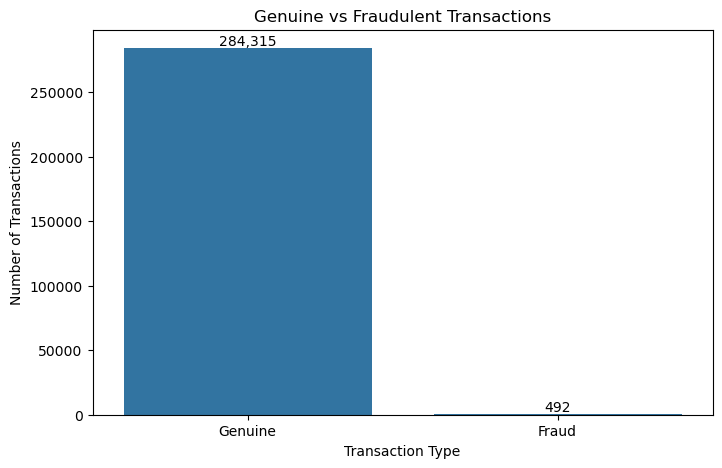

In [11]:
# Transaction distribution

class_counts = df['Class'].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=['Genuine', 'Fraud'],
    y=[class_counts[0], class_counts[1]]
)

plt.title('Genuine vs Fraudulent Transactions')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Transactions')

for i, value in enumerate([class_counts[0], class_counts[1]]):
    plt.text(i, value, f'{value:,}', ha='center', va='bottom')

plt.show()

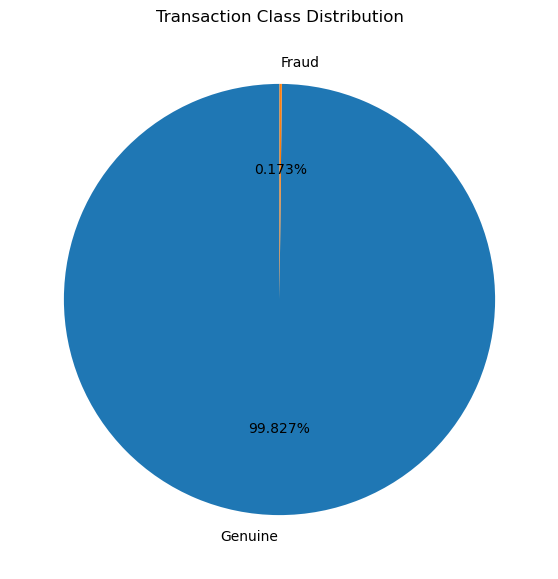

In [12]:
plt.figure(figsize=(7, 7))

plt.pie(
    [class_counts[0], class_counts[1]],
    labels=['Genuine', 'Fraud'],
    autopct='%1.3f%%',
    startangle=90
)

plt.title('Transaction Class Distribution')
plt.show()

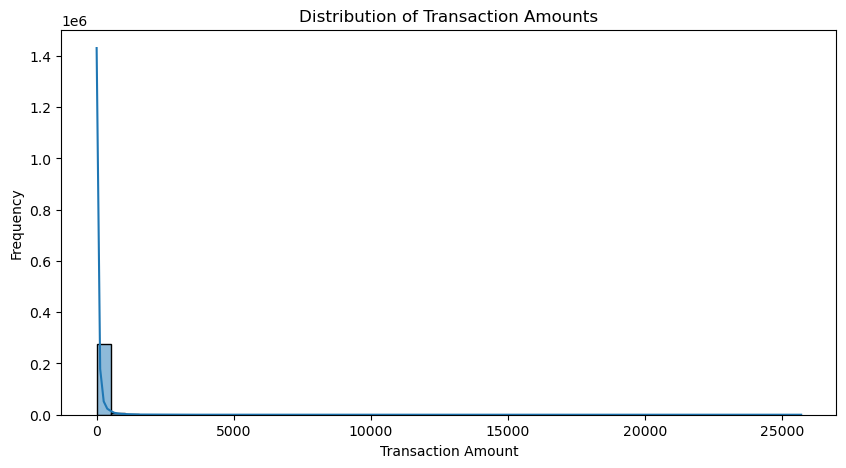

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='Amount',
    bins=50,
    kde=True
)

plt.title('Distribution of Transaction Amounts')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')
plt.show()

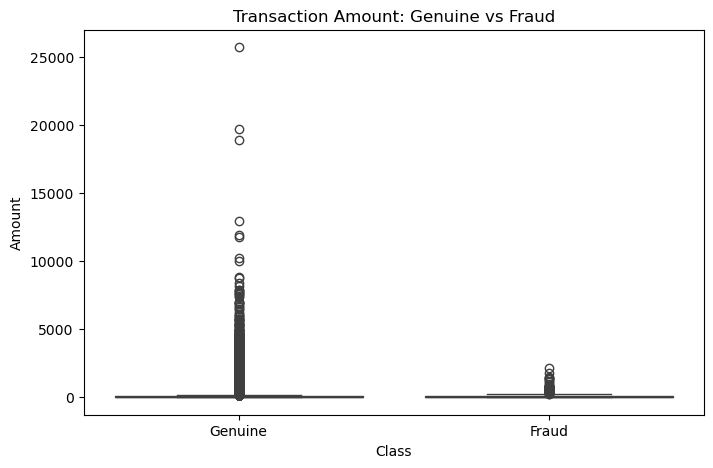

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Class',
    y='Amount'
)

plt.title('Transaction Amount: Genuine vs Fraud')
plt.xticks([0, 1], ['Genuine', 'Fraud'])
plt.show()

In [15]:
# Separate input features and target variable

X = df.drop('Class', axis=1)
y = df['Class']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (284807, 30)
Target shape: (284807,)


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nFraud cases in training:", y_train.sum())
print("Fraud cases in testing:", y_test.sum())

Training records: 227845
Testing records: 56962

Fraud cases in training: 394
Fraud cases in testing: 98


In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

preprocessor = make_column_transformer(
    (StandardScaler(), ['Time', 'Amount']),
    remainder='passthrough'
)

logistic_model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [18]:
y_pred = logistic_model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

# Get fraud probabilities
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("LOGISTIC REGRESSION - PERFORMANCE")
print("----------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("PR-AUC:", average_precision_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

LOGISTIC REGRESSION - PERFORMANCE
----------------------------------
Accuracy: 0.9755275446789088
Precision: 0.06097560975609756
Recall: 0.9183673469387755
F1 Score: 0.11435832274459974
ROC-AUC: 0.9721687370080279
PR-AUC: 0.7159122424484009

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962



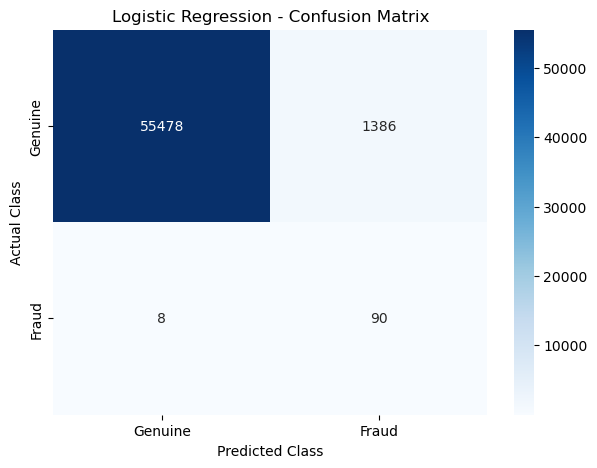

Confusion Matrix:
[[55478  1386]
 [    8    90]]


In [20]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Genuine', 'Fraud'],
    yticklabels=['Genuine', 'Fraud']
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

print("Confusion Matrix:")
print(cm)

In [23]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Create Decision Tree model
decision_tree = DecisionTreeClassifier(
    max_depth=8,
    min_samples_leaf=10,
    class_weight='balanced',
    random_state=42
)

# Train model
decision_tree.fit(X_train, y_train)

# Make predictions
dt_pred = decision_tree.predict(X_test)
dt_prob = decision_tree.predict_proba(X_test)[:, 1]

# Display results
print("DECISION TREE RESULTS")
print("=====================")

print(f"Accuracy  : {accuracy_score(y_test, dt_pred):.4f}")
print(f"Precision : {precision_score(y_test, dt_pred):.4f}")
print(f"Recall    : {recall_score(y_test, dt_pred):.4f}")
print(f"F1 Score  : {f1_score(y_test, dt_pred):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, dt_prob):.4f}")
print(f"PR-AUC    : {average_precision_score(y_test, dt_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

DECISION TREE RESULTS
Accuracy  : 0.9804
Precision : 0.0686
Recall    : 0.8265
F1 Score  : 0.1267
ROC-AUC   : 0.9075
PR-AUC    : 0.4748

Confusion Matrix:
[[55764  1100]
 [   17    81]]


In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix
)

# Create Random Forest model
random_forest = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Train model
random_forest.fit(X_train, y_train)

# Predictions
rf_pred = random_forest.predict(X_test)
rf_prob = random_forest.predict_proba(X_test)[:, 1]

# Results
print("RANDOM FOREST RESULTS")
print("=====================")

print(f"Accuracy  : {accuracy_score(y_test, rf_pred):.4f}")
print(f"Precision : {precision_score(y_test, rf_pred):.4f}")
print(f"Recall    : {recall_score(y_test, rf_pred):.4f}")
print(f"F1 Score  : {f1_score(y_test, rf_pred):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, rf_prob):.4f}")
print(f"PR-AUC    : {average_precision_score(y_test, rf_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

RANDOM FOREST RESULTS
Accuracy  : 0.9994
Precision : 0.8265
Recall    : 0.8265
F1 Score  : 0.8265
ROC-AUC   : 0.9833
PR-AUC    : 0.8547

Confusion Matrix:
[[56847    17]
 [   17    81]]


In [25]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

results = []

models = {
    "Logistic Regression": (logistic_model, y_pred, y_prob),
    "Decision Tree": (decision_tree, dt_pred, dt_prob),
    "Random Forest": (random_forest, rf_pred, rf_prob)
}

for name, (model, predictions, probabilities) in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities)
    })

comparison_df = pd.DataFrame(results)

print("MODEL COMPARISON")
display(comparison_df.round(4))

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.9755,0.0610,0.9184,0.1144,0.9722,0.7159
1,Decision Tree,0.9804,0.0686,0.8265,0.1267,0.9075,0.4748
2,Random Forest,0.9994,0.8265,0.8265,0.8265,0.9833,0.8547


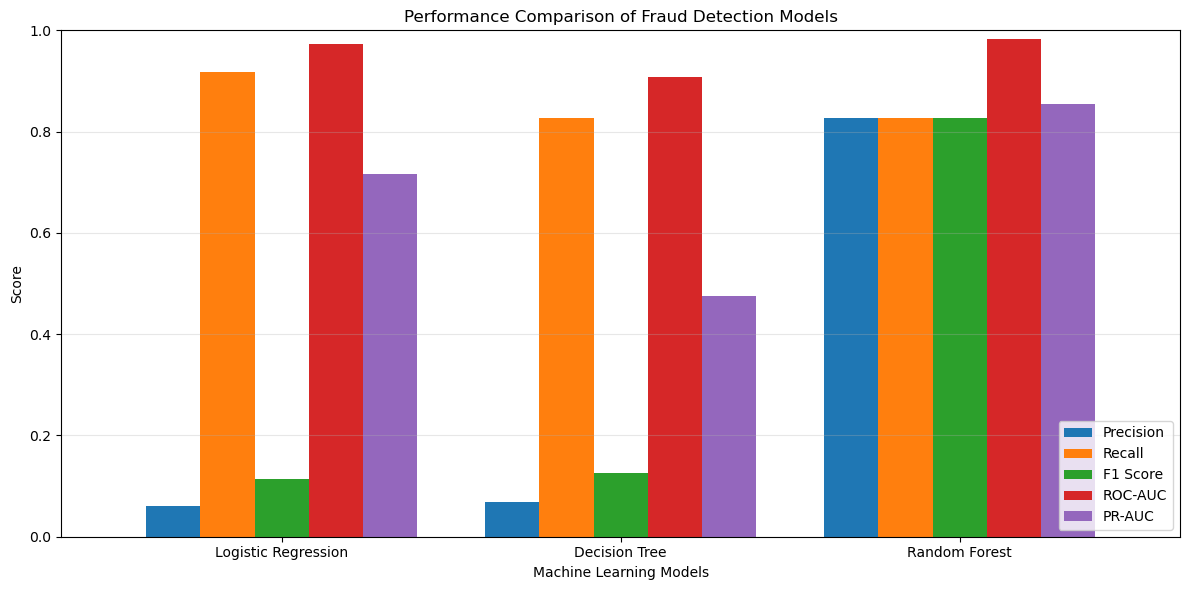

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics = ["Precision", "Recall", "F1 Score", "ROC-AUC", "PR-AUC"]

comparison_plot = comparison_df.set_index("Model")[metrics]

comparison_plot.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.8
)

plt.title("Performance Comparison of Fraud Detection Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
from sklearn.metrics import classification_report

print("RANDOM FOREST CLASSIFICATION REPORT")
print("===================================")

print(classification_report(
    y_test,
    rf_pred,
    target_names=["Genuine", "Fraud"],
    digits=4
))

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Genuine     0.9997    0.9997    0.9997     56864
       Fraud     0.8265    0.8265    0.8265        98

    accuracy                         0.9994     56962
   macro avg     0.9131    0.9131    0.9131     56962
weighted avg     0.9994    0.9994    0.9994     56962



TOP 15 IMPORTANT FEATURES


,Feature,Importance
14,V14,0.1839
10,V10,0.1184
12,V12,0.1000
17,V17,0.0947
4,V4,0.0916
3,V3,0.0674
11,V11,0.0552
16,V16,0.0388
2,V2,0.0387
9,V9,0.0275


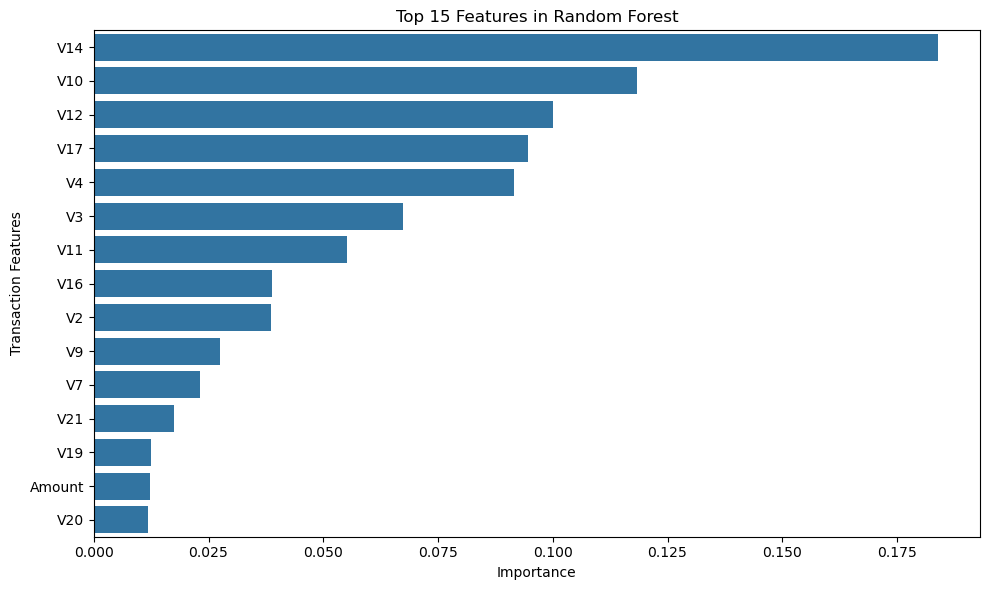

In [28]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 15 IMPORTANT FEATURES")
display(feature_importance.head(15).round(4))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features in Random Forest")
plt.xlabel("Importance")
plt.ylabel("Transaction Features")
plt.tight_layout()
plt.show()

In [29]:
import os

OUTPUT_DIR = r"C:\FraudDetection\ml-service\outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

comparison_df.to_csv(
    os.path.join(OUTPUT_DIR, "model_comparison.csv"),
    index=False
)

print("Model comparison saved successfully!")
print("File: model_comparison.csv")

Model comparison saved successfully!
File: model_comparison.csv


In [30]:
from sklearn.model_selection import train_test_split

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training rows  :", len(X_subtrain))
print("Validation rows:", len(X_val))
print("Test rows      :", len(X_test))

print("\nFraud transactions in validation:", int(y_val.sum()))

Training rows  : 182276
Validation rows: 45569
Test rows      : 56962

Fraud transactions in validation: 79


In [31]:
validation_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

validation_rf.fit(X_subtrain, y_subtrain)

val_prob = validation_rf.predict_proba(X_val)[:, 1]

print("Validation Random Forest trained successfully!")

Validation Random Forest trained successfully!


In [32]:
from sklearn.metrics import precision_recall_curve
import numpy as np

precision_values, recall_values, thresholds = precision_recall_curve(
    y_val,
    val_prob
)

f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (precision_values[:-1] + recall_values[:-1] + 1e-10)
)

best_index = np.argmax(f1_values)
best_threshold = thresholds[best_index]

print("BEST THRESHOLD RESULTS")
print("======================")
print(f"Best Threshold : {best_threshold:.4f}")
print(f"Precision      : {precision_values[best_index]:.4f}")
print(f"Recall         : {recall_values[best_index]:.4f}")
print(f"F1 Score       : {f1_values[best_index]:.4f}")

BEST THRESHOLD RESULTS
Best Threshold : 0.4954
Precision      : 0.8714
Recall         : 0.7722
F1 Score       : 0.8188


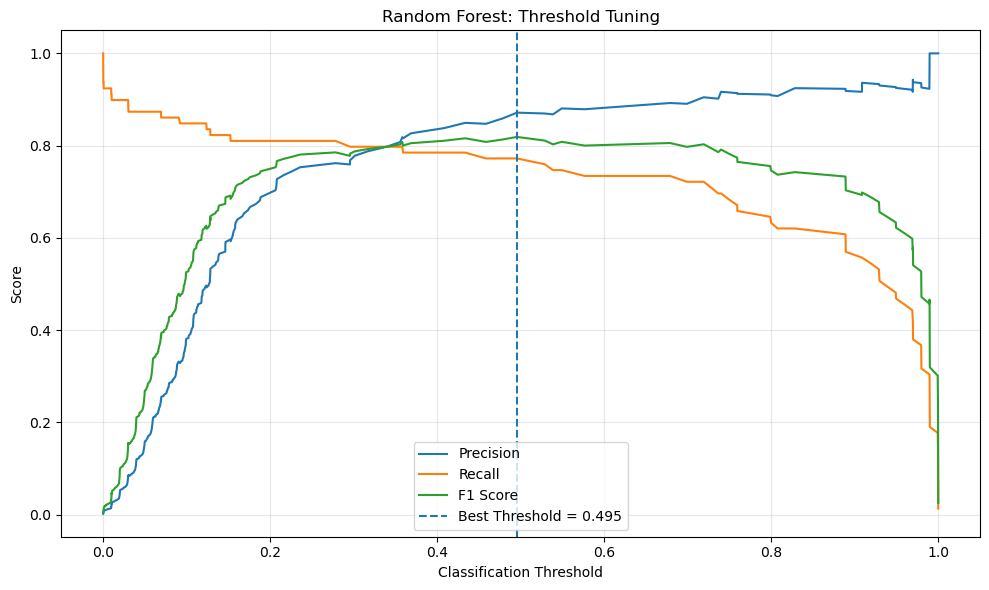

In [33]:
plt.figure(figsize=(10, 6))

plt.plot(thresholds, precision_values[:-1], label="Precision")
plt.plot(thresholds, recall_values[:-1], label="Recall")
plt.plot(thresholds, f1_values, label="F1 Score")

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best Threshold = {best_threshold:.3f}"
)

plt.title("Random Forest: Threshold Tuning")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:
final_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train, y_train)

final_prob = final_model.predict_proba(X_test)[:, 1]

final_pred = (
    final_prob >= best_threshold
).astype(int)

print("FINAL RANDOM FOREST RESULTS")
print("===========================")

print(f"Threshold : {best_threshold:.4f}")
print(f"Accuracy  : {accuracy_score(y_test, final_pred):.4f}")
print(f"Precision : {precision_score(y_test, final_pred):.4f}")
print(f"Recall    : {recall_score(y_test, final_pred):.4f}")
print(f"F1 Score  : {f1_score(y_test, final_pred):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, final_prob):.4f}")
print(f"PR-AUC    : {average_precision_score(y_test, final_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_pred))

FINAL RANDOM FOREST RESULTS
Threshold : 0.4954
Accuracy  : 0.9994
Precision : 0.8265
Recall    : 0.8265
F1 Score  : 0.8265
ROC-AUC   : 0.9833
PR-AUC    : 0.8547

Confusion Matrix:
[[56847    17]
 [   17    81]]


In [35]:
import joblib
import os

OUTPUT_DIR = r"C:\FraudDetection\ml-service\outputs"
MODEL_DIR = r"C:\FraudDetection\ml-service\models"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

model_path = os.path.join(
    MODEL_DIR,
    "random_forest_fraud_model.joblib"
)

joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: C:\FraudDetection\ml-service\models\random_forest_fraud_model.joblib


In [36]:
import json
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, final_pred)

metrics = {
    "model_name": "Random Forest",
    "threshold": float(best_threshold),
    "accuracy": float(accuracy_score(y_test, final_pred)),
    "precision": float(precision_score(y_test, final_pred)),
    "recall": float(recall_score(y_test, final_pred)),
    "f1_score": float(f1_score(y_test, final_pred)),
    "roc_auc": float(roc_auc_score(y_test, final_prob)),
    "pr_auc": float(average_precision_score(y_test, final_prob)),
    "confusion_matrix": cm.tolist(),
    "training_records": int(len(X_train)),
    "testing_records": int(len(X_test))
}

metrics_path = os.path.join(
    OUTPUT_DIR,
    "model_metrics.json"
)

with open(metrics_path, "w") as file:
    json.dump(metrics, file, indent=4)

print("Metrics saved successfully!")
print("Location:", metrics_path)

print("\nSaved metrics:")
print(json.dumps(metrics, indent=4))

Metrics saved successfully!
Location: C:\FraudDetection\ml-service\outputs\model_metrics.json

Saved metrics:
{
    "model_name": "Random Forest",
    "threshold": 0.49539234499074425,
    "accuracy": 0.999403110845827,
    "precision": 0.826530612244898,
    "recall": 0.826530612244898,
    "f1_score": 0.826530612244898,
    "roc_auc": 0.9833441659584486,
    "pr_auc": 0.8546568126999035,
    "confusion_matrix": [
        [
            56847,
            17
        ],
        [
            17,
            81
        ]
    ],
    "training_records": 227845,
    "testing_records": 56962
}


In [37]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": final_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

importance_path = os.path.join(
    OUTPUT_DIR,
    "feature_importance.csv"
)

feature_importance.to_csv(
    importance_path,
    index=False
)

print("Feature importance saved!")
display(feature_importance.head(15).round(4))

Feature importance saved!


,Feature,Importance
14,V14,0.1839
10,V10,0.1184
12,V12,0.1000
17,V17,0.0947
4,V4,0.0916
3,V3,0.0674
11,V11,0.0552
16,V16,0.0388
2,V2,0.0387
9,V9,0.0275


In [38]:
predictions_df = X_test.copy()

predictions_df["Actual_Class"] = y_test.values
predictions_df["Fraud_Probability"] = final_prob
predictions_df["Predicted_Class"] = final_pred

predictions_df["Prediction_Status"] = predictions_df[
    "Predicted_Class"
].map({
    0: "Genuine",
    1: "Suspicious"
})

predictions_path = os.path.join(
    OUTPUT_DIR,
    "test_predictions.csv"
)

predictions_df.to_csv(
    predictions_path,
    index=False
)

print("Test predictions exported successfully!")
print("Total records:", len(predictions_df))
print("Location:", predictions_path)

display(predictions_df.head(10))

Test predictions exported successfully!
Total records: 56962
Location: C:\FraudDetection\ml-service\outputs\test_predictions.csv


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V24,V25,V26,V27,V28,Amount,Actual_Class,Fraud_Probability,Predicted_Class,Prediction_Status
263020,160760.0,-0.674466,1.408105,-1.110622,-1.328366,1.388996,-1.308439,1.885879,-0.614233,0.311652,...,0.707899,-0.135837,0.045102,0.533837,0.291319,23.00,0,0.000052,0,Genuine
11378,19847.0,-2.829816,-2.765149,2.537793,-1.074580,2.842559,-2.153536,-1.795519,-0.250020,3.073504,...,0.042996,-0.027660,-0.910247,0.110802,-0.511938,11.85,0,0.006631,0,Genuine
147283,88326.0,-3.576495,2.318422,1.306985,3.263665,1.127818,2.865246,1.444125,-0.718922,1.874046,...,-1.483996,-0.296011,0.062823,0.552411,0.509764,76.07,0,0.019871,0,Genuine
219439,141734.0,2.060386,-0.015382,-1.082544,0.386019,-0.024331,-1.074935,0.207792,-0.338140,0.455091,...,-0.067584,-0.283675,0.203529,-0.063621,-0.060077,0.99,0,0.000159,0,Genuine
36939,38741.0,1.209965,1.384303,-1.343531,1.763636,0.662351,-2.113384,0.854039,-0.475963,-0.629658,...,0.619449,0.818998,-0.330525,0.046884,0.104527,1.50,0,0.085852,0,Genuine
243438,151934.0,-0.345588,1.070328,-0.652790,-0.492207,0.749482,-0.949391,0.752520,0.079095,0.061269,...,0.618295,-0.438012,0.073463,-0.196700,-0.211518,8.99,0,0.002158,0,Genuine
259448,159122.0,-0.864273,0.361412,-0.346667,-1.938227,-1.065839,-1.056202,-0.093590,0.095647,-2.782531,...,-0.033647,-0.488660,-0.234982,-0.578365,-0.225400,52.00,0,0.000192,0,Genuine
43800,41656.0,-1.679000,0.004724,2.093100,-0.209994,1.112123,-1.254060,0.193846,-0.010860,-0.568361,...,0.409963,0.137482,0.013113,-0.143778,0.184565,3.59,0,0.000828,0,Genuine
66742,52202.0,-0.806445,0.865983,1.105898,1.383957,-0.018110,0.140882,0.124651,0.603672,-0.853074,...,0.258955,-0.367384,-0.308236,0.083590,0.059612,27.92,0,0.007531,0,Genuine
66499,52081.0,1.169646,-0.823924,0.467031,-0.840968,-0.850688,0.062139,-0.705097,0.094004,-1.020702,...,-0.291176,0.171156,-0.390048,0.017274,0.023729,95.25,0,0.000470,0,Genuine


In [39]:
print("SAVED PROJECT FILES")
print("===================")

for folder in [MODEL_DIR, OUTPUT_DIR]:
    print(f"\nFolder: {folder}")

    for filename in os.listdir(folder):
        filepath = os.path.join(folder, filename)

        if os.path.isfile(filepath):
            size_kb = os.path.getsize(filepath) / 1024
            print(f"{filename} - {size_kb:.2f} KB")

SAVED PROJECT FILES

Folder: C:\FraudDetection\ml-service\models
random_forest_fraud_model.joblib - 2002.43 KB

Folder: C:\FraudDetection\ml-service\outputs
feature_importance.csv - 0.76 KB
model_comparison.csv - 0.44 KB
model_metrics.json - 0.49 KB
test_predictions.csv - 31271.01 KB


In [40]:
import os

folders = [
    r"C:\FraudDetection\ml-service\models",
    r"C:\FraudDetection\ml-service\outputs"
]

for folder in folders:
    print(f"\n{folder}")
    for filename in os.listdir(folder):
        print("  ✓", filename)


C:\FraudDetection\ml-service\models
  ✓ random_forest_fraud_model.joblib

C:\FraudDetection\ml-service\outputs
  ✓ feature_importance.csv
  ✓ model_comparison.csv
  ✓ model_metrics.json
  ✓ test_predictions.csv
